# BT4012 Fraud Analytics Group 14: RGCN

## Libraries

In [1]:
from pathlib import Path
import platform
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.preprocessing import RobustScaler

## Configuration

In [2]:
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
GRAPH_DIR = PROCESSED_DIR / "graph"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
EMBEDDING_DIR = RESULTS_DIR / "rgcn_embeddings"

KEYS = ["nodeID", "Year"]
DROP_RELATIONS = ["shared_related_org"]
DROP_FEATURE_SUFFIXES = ("_yoy", "_was_missing")

HIDDEN_SIZE = 64
DROPOUT = 0.3
LEARNING_RATE = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 30
SEED = 0
MLP_SETTINGS = dict(n_layers=2, skip=False)
RGCN_SETTINGS = dict(n_layers=2, skip=True)

TRAINING_SETTINGS = dict(dropout=0.5, weight_decay=5e-3, stop_metric="pr_auc")
FIRST_TIME_TRAINING = True
HISTORY_FIRST_RANKING = True
REFIT_ON_VALIDATION = False
CONTINUATION_MODEL = True
N_SEEDS = 1
TUNING_SEEDS = [0, 1, 2]
FLAG_SHARE = 0.05

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Hardware

In [3]:
HARDWARE = {
    "cpu": "AMD Ryzen 7 7435HS, 8 cores / 16 threads",
    "ram": "28 GB DDR5",
    "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU, 8 GB",
}
torch.set_num_threads(8)

print(f"python {platform.python_version()} | torch {torch.__version__} | CUDA build {torch.version.cuda}")
for part, description in HARDWARE.items():
    print(f"{part:<4} {description}")
if DEVICE.type == "cuda":
    gpu = torch.cuda.get_device_properties(0)
    print(f"running on {gpu.name}, {gpu.total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA not available, running on CPU")

python 3.12.16 | torch 2.14.0+cu132 | CUDA build 13.2
cpu  AMD Ryzen 7 7435HS, 8 cores / 16 threads
ram  28 GB DDR5
gpu  NVIDIA GeForce RTX 4060 Laptop GPU, 8 GB
running on NVIDIA GeForce RTX 4060 Laptop GPU, 8.6 GB


## Loading pipeline outputs

In [4]:
def read_table(path):
    table = pd.read_parquet(path) if path.suffix != ".csv" else pd.read_csv(path)
    return table.astype({"Year": "int64"})

temporal_splits = read_table(DATA_DIR / "splits" / "temporal_splits.csv")
company_edges = read_table(GRAPH_DIR / "company_edges.parquet")
degree_features = read_table(GRAPH_DIR / "degree_features.csv")
text_features = read_table(PROCESSED_DIR / "text_features.parquet")
text_embeddings = read_table(PROCESSED_DIR / "text_embeddings.parquet")

TEST_YEAR_BY_SPLIT = (temporal_splits[temporal_splits["role"] == "test"].groupby("split")["Year"].first().astype(int).to_dict())
TEST_YEARS = list(TEST_YEAR_BY_SPLIT.values())
DEGREE_COLUMNS = [column for column in degree_features.columns if column not in KEYS]
TEXT_COLUMNS = {column for column in [*text_features.columns, *text_embeddings.columns] if column not in KEYS}

for name, table in {"temporal_splits": temporal_splits,
                    "company_edges": company_edges,
                    "degree_features": degree_features,
                    "text_features": text_features,
                    "text_embeddings": text_embeddings}.items():
    print(f"{name:<16} {len(table):>12,} rows  {table.shape[1]:>4} columns")
print("test year per split:", TEST_YEAR_BY_SPLIT)

temporal_splits       105,453 rows     5 columns
company_edges      13,157,706 rows     4 columns
degree_features        33,634 rows     6 columns
text_features          33,664 rows    10 columns
text_embeddings        33,664 rows    66 columns
test year per split: {0: 2019, 1: 2020, 2: 2021, 3: 2022}


## Edges

In [5]:
graph_edges = company_edges[~company_edges["relation"].isin(DROP_RELATIONS)]
RELATIONS = sorted(graph_edges["relation"].unique())

company_years = (temporal_splits[KEYS + ["Label"]].drop_duplicates(KEYS).sort_values(["Year", "nodeID"], ignore_index=True))
row_lookup = pd.MultiIndex.from_frame(company_years[KEYS])

def row_numbers(company_column):
    return row_lookup.get_indexer(pd.MultiIndex.from_arrays([graph_edges[company_column], graph_edges["Year"]]))

edge_list = pd.DataFrame({
    "source": row_numbers("source_id"),
    "target": row_numbers("target_id"),
    "relation": graph_edges["relation"].map({relation: i for i, relation in enumerate(RELATIONS)}).to_numpy(),
    "Year": graph_edges["Year"].to_numpy(),
})
assert (edge_list[["source", "target"]] >= 0).all().all(), "an edge points to a company-year with no features"

print(f"company-years: {len(company_years):,}")
print(f"edges: {len(company_edges):,} -> {len(edge_list):,} after dropping {', '.join(DROP_RELATIONS)}")
edge_list.groupby("relation").size().set_axis(RELATIONS).rename("edges").to_frame()

company-years: 33,664
edges: 13,157,706 -> 13,157,604 after dropping shared_related_org


,edges
Investment,141934
individual_investor_and_related_party,35128
org_investor_and_related_party,5468
related_party_transaction,20890
shared_auditor,8665326
shared_individual_investor,197878
shared_org_investor,451376
shared_related_individual,732956
shared_related_unlisted_firm,70146
shared_unlisted_investment,2757824


## Node features for each split

In [6]:
def load_split_table(split):
    rows = temporal_splits.loc[temporal_splits["split"] == split, KEYS + ["Label", "role"]]
    tabular = read_table(PROCESSED_DIR / "tabular_features_folds" / f"split_{split}")
    tfidf = read_table(PROCESSED_DIR / "text_tfidf" / f"split_{split}.parquet")

    table = rows
    for source in [tabular, text_features, text_embeddings, tfidf, degree_features]:
        table = table.merge(source, on=KEYS, how="left", validate="one_to_one")
    table[DEGREE_COLUMNS] = table[DEGREE_COLUMNS].fillna(0)
    return table.sort_values(["Year", "nodeID"], ignore_index=True)

def model_feature_columns(table):
    return [column for column in table.columns if column not in KEYS + ["Label", "role"] and not column.endswith(DROP_FEATURE_SUFFIXES)]

def scale_features(table, columns):
    features = table[columns].astype("float64")
    train_rows = table["role"] == "train"
    text_columns = [column for column in columns if column in TEXT_COLUMNS or column.startswith("tfidf_")]

    features[DEGREE_COLUMNS] = np.log1p(features[DEGREE_COLUMNS])
    for group in [DEGREE_COLUMNS, text_columns]:
        scaler = RobustScaler().fit(features.loc[train_rows, group])
        features[group] = scaler.transform(features[group])
    features = np.sign(features) * np.log1p(features.abs())

    assert np.isfinite(features.to_numpy()).all(), "features contain NaN or inf"
    return features.to_numpy(np.float32)

## Fraud history

In [7]:
def fraud_last_year(table):
    earlier = table[["nodeID", "Year", "Label"]].assign(Year=table["Year"] + 1)
    return table[KEYS].merge(earlier, on=KEYS, how="left", validate="one_to_one")["Label"]

def add_fraud_history(table, features):
    last_year = fraud_last_year(table)
    history = np.column_stack([last_year.fillna(0), last_year.notna()]).astype(np.float32)
    return np.column_stack([features, history]).astype(np.float32)

def repeat_candidates(table):
    return fraud_last_year(table).fillna(0).to_numpy() == 1

## Graph for each split

In [8]:
def build_adjacency(edges, n_nodes):
    matrices = []
    for relation in range(len(RELATIONS)):
        chosen = edges[edges["relation"] == relation]
        receiver = torch.tensor(chosen["target"].to_numpy(), dtype=torch.long)
        sender = torch.tensor(chosen["source"].to_numpy(), dtype=torch.long)
        n_links = torch.bincount(receiver, minlength=n_nodes).clamp(min=1).float()
        matrix = torch.sparse_coo_tensor(torch.stack([receiver, sender]), 1.0 / n_links[receiver], (n_nodes, n_nodes), check_invariants=False)
        matrices.append(matrix.coalesce().to(DEVICE))
    return matrices

def load_split(split):
    test_year = TEST_YEAR_BY_SPLIT[split]
    table = load_split_table(split)
    n_nodes = len(table)

    same_rows = (np.array_equal(table["nodeID"], company_years["nodeID"].iloc[:n_nodes]) and np.array_equal(table["Year"], company_years["Year"].iloc[:n_nodes]))
    assert same_rows, f"split {split}: rows are not every company-year up to {test_year}"
    assert table["Year"].max() == test_year, f"split {split}: last year is not the test year"

    columns = model_feature_columns(table)
    features = add_fraud_history(table, scale_features(table, columns))
    adjacency = build_adjacency(edge_list[edge_list["Year"] <= test_year], n_nodes)
    return table, features, adjacency

## Model

In [9]:
class RGCNLayer(nn.Module):
    def __init__(self, in_size, out_size, n_relations):
        super().__init__()
        self.self_weight = nn.Linear(in_size, out_size)
        self.relation_weights = nn.ModuleList(nn.Linear(in_size, out_size, bias=False) for _ in range(n_relations))

    def forward(self, hidden, adjacency):
        output = self.self_weight(hidden)
        for matrix, weight in zip(adjacency, self.relation_weights):
            output = output + torch.sparse.mm(matrix, weight(hidden))
        return output

class RGCN(nn.Module):
    def __init__(self, n_features, n_relations, n_layers=2, skip=False, hidden_size=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        self.input_layer = nn.Linear(n_features, hidden_size)
        self.graph_layers = nn.ModuleList(RGCNLayer(hidden_size, hidden_size, n_relations) for _ in range(n_layers))
        self.skip = skip
        classifier_size = hidden_size * (n_layers + 1) if skip else hidden_size
        self.classifier = nn.Linear(classifier_size, 1)
        self.dropout = nn.Dropout(dropout)

    def embed(self, x, adjacency):
        hidden = self.dropout(F.relu(self.input_layer(x)))
        layer_outputs = [hidden]
        for layer in self.graph_layers:
            hidden = self.dropout(F.relu(layer(hidden, adjacency)))
            layer_outputs.append(hidden)
        return torch.cat(layer_outputs, dim=1) if self.skip else hidden

    def forward(self, x, adjacency):
        return self.classifier(self.embed(x, adjacency)).squeeze(1)

## Training

In [10]:
def predict(model, x, adjacency):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(x, adjacency)).cpu().numpy()

def train_model(x, y, adjacency, train_mask, val_mask=None, n_layers=2, skip=False, seed=SEED, dropout=DROPOUT,
                weight_decay=WEIGHT_DECAY, stop_metric="roc_auc", n_epochs=None, learning_rate=LEARNING_RATE, hidden_size=HIDDEN_SIZE):
    torch.manual_seed(seed)
    model = RGCN(x.shape[1], len(adjacency), n_layers, skip, hidden_size=hidden_size, dropout=dropout).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    fraud_weight = (y[train_mask] == 0).sum() / (y[train_mask] == 1).sum()
    early_stopping = n_epochs is None
    if early_stopping:
        val_rows = val_mask.cpu().numpy()
        val_labels = y.cpu().numpy()[val_rows]

    history = []
    best_score, best_epoch, best_state, epochs_without_improvement = -1.0, 0, None, 0
    for epoch in range(1, (n_epochs or MAX_EPOCHS) + 1):
        model.train()
        optimizer.zero_grad()
        logits = model(x, adjacency)
        loss = F.binary_cross_entropy_with_logits(logits[train_mask], y[train_mask], pos_weight=fraud_weight)
        loss.backward()
        optimizer.step()
        if not early_stopping:
            history.append({"epoch": epoch, "loss": loss.item()})
            continue

        val_scores = predict(model, x, adjacency)[val_rows]
        record = {"epoch": epoch,
                  "loss": loss.item(),
                  "val_roc_auc": roc_auc_score(val_labels, val_scores),
                  "val_pr_auc": average_precision_score(val_labels, val_scores)}
        history.append(record)
        if record[f"val_{stop_metric}"] > best_score:
            best_score, best_epoch, epochs_without_improvement = record[f"val_{stop_metric}"], epoch, 0
            best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    if early_stopping:
        model.load_state_dict(best_state)
    else:
        best_epoch = n_epochs
    return model, best_epoch, pd.DataFrame(history)

def fit_and_predict(x, y, graph, years, test_year, seed=SEED, refit=False, usable_rows=None, **settings):
    usable = np.ones(len(years), dtype=bool) if usable_rows is None else usable_rows
    val_year = test_year - 1
    train_mask = torch.tensor(usable & (years < val_year), device=DEVICE)
    val_mask = torch.tensor(usable & (years == val_year), device=DEVICE)
    model, best_epoch, history = train_model(x, y, graph, train_mask, val_mask, seed=seed, **settings)
    if refit:
        refit_mask = torch.tensor(usable & (years < test_year), device=DEVICE)
        model, _, _ = train_model(x, y, graph, refit_mask, seed=seed, n_epochs=best_epoch, **settings)
    return model, predict(model, x, graph), best_epoch, history

def fit_scores(x, y, graph, years, test_year, repeat, seed=SEED, refit=False, first_time=False, continuation=False, **settings):
    usable_rows = ~repeat if first_time else None
    model, scores, best_epoch, history = fit_and_predict(x, y, graph, years, test_year, seed, refit, usable_rows, **settings)
    if continuation:
        _, continuation_scores, _, _ = fit_and_predict(x, y, graph, years, test_year, seed, refit, repeat, **settings)
        scores = np.where(repeat, continuation_scores, scores)
    return model, scores, best_epoch, history

## Evaluation helpers

In [11]:
def recall_at_top(labels, scores, share=FLAG_SHARE):
    flagged = np.argsort(-scores)[:int(np.ceil(share * len(scores)))]
    return labels[flagged].sum() / labels.sum()

def final_ranking(scores, repeat):
    return scores + repeat if HISTORY_FIRST_RANKING else scores

def evaluate(model_name, split, test_year, scores, labels, years, repeat,
             best_epoch=np.nan, seconds=np.nan, peak_gpu_gb=np.nan):
    test_rows, val_rows = years == test_year, years == test_year - 1
    first_time = test_rows & ~repeat
    last_year_frauds = test_rows & repeat
    ranked = final_ranking(scores, repeat)
    return {"model": model_name,
            "split": split,
            "test_year": test_year,
            "best_epoch": best_epoch,
            "val_auc": np.nan if REFIT_ON_VALIDATION else roc_auc_score(labels[val_rows], ranked[val_rows]),
            "test_auc": roc_auc_score(labels[test_rows], ranked[test_rows]),
            "test_pr_auc": average_precision_score(labels[test_rows], ranked[test_rows]),
            "test_top5_recall": recall_at_top(labels[test_rows], ranked[test_rows]),
            "first_time_auc": roc_auc_score(labels[first_time], scores[first_time]),
            "first_time_pr_auc": average_precision_score(labels[first_time], scores[first_time]),
            "repeat_pr_auc": average_precision_score(labels[last_year_frauds], scores[last_year_frauds]),
            "test_fraud_rate": labels[test_rows].mean(),
            "seconds": seconds,
            "peak_gpu_gb": peak_gpu_gb}

def save_hidden_vectors(model, x, adjacency, table, split, scores):
    model.eval()
    with torch.no_grad():
        hidden = model.embed(x, adjacency).cpu().numpy()
    val_year = TEST_YEAR_BY_SPLIT[split] - 1
    info = table[KEYS + ["Label"]].assign(
        role=np.select([table["Year"] < val_year, table["Year"] == val_year], ["train", "val"], "test"), rgcn_score=scores)
    vectors = pd.DataFrame(hidden, columns=[f"h{i}" for i in range(hidden.shape[1])])
    pd.concat([info, vectors], axis=1).to_parquet(EMBEDDING_DIR / f"split_{split}.parquet", index=False)

## Choosing settings on a holdout year

In [12]:
METRIC_NAMES = ["first_time_pr_auc", "repeat_pr_auc", "top5_recall", "first_time_roc_auc"]

def holdout_metrics(labels, scores, repeat):
    first_time = ~repeat
    return {"first_time_pr_auc": average_precision_score(labels[first_time], scores[first_time]),
            "repeat_pr_auc": average_precision_score(labels[repeat], scores[repeat]),
            "top5_recall": recall_at_top(labels, final_ranking(scores, repeat)),
            "first_time_roc_auc": roc_auc_score(labels[first_time], scores[first_time])}

def run_holdout_experiment(candidates, seeds=TUNING_SEEDS):
    runs = []
    for split, test_year in TEST_YEAR_BY_SPLIT.items():
        holdout_year = test_year - 1
        table, features, adjacency = load_split(split)
        years = table["Year"].to_numpy()
        labels = table["Label"].to_numpy()
        repeat = repeat_candidates(table)
        holdout = years == holdout_year
        x = torch.tensor(features, device=DEVICE)
        y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)

        for name, candidate in candidates.items():
            settings = {**TRAINING_SETTINGS, **candidate}
            refit = settings.pop("refit", REFIT_ON_VALIDATION)
            first_time = settings.pop("first_time", FIRST_TIME_TRAINING)
            continuation = settings.pop("continuation", CONTINUATION_MODEL)
            for seed in seeds:
                scores = {}
                for model_name, graph, architecture in [("mlp", [], MLP_SETTINGS), ("rgcn", adjacency, RGCN_SETTINGS)]:
                    _, scores[model_name], _, _ = fit_scores(x, y, graph, years, holdout_year, repeat, seed, refit, first_time, continuation, **architecture, **settings)
                scores["ens"] = (scores["mlp"] + scores["rgcn"]) / 2
                for model_name, model_scores in scores.items():
                    runs.append({"candidate": name,
                                 "model": model_name,
                                 "split": split,
                                 "seed": seed,
                                 "labels": labels[holdout],
                                 "scores": model_scores[holdout],
                                 "repeat": repeat[holdout]})
        print(f"split {split} done (holdout year {holdout_year})")
        del x, y, adjacency
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return pd.DataFrame(runs)

def summarise_holdout(runs):
    single = pd.DataFrame([{"candidate": run.candidate,
                            "model": run.model,
                            "seed": run.seed,
                            **holdout_metrics(run.labels, run.scores, run.repeat)} for run in runs.itertuples()])
    per_seed = single.groupby(["candidate", "model", "seed"], sort=False)[METRIC_NAMES].mean()
    summary = per_seed.groupby(level=["candidate", "model"], sort=False).agg(["mean", "std"])

    averaged = pd.DataFrame([{"candidate": candidate,
                              "model": model_name,
                              **holdout_metrics(group["labels"].iloc[0],
                                                np.mean(np.stack(group["scores"].to_list()), axis=0),
                                                group["repeat"].iloc[0])}
                             for (candidate, model_name, _), group in runs.groupby(["candidate", "model", "split"], sort=False)])
    averaged = averaged.groupby(["candidate", "model"], sort=False)[METRIC_NAMES].mean()
    for metric in METRIC_NAMES:
        summary[(metric, "seed average")] = averaged[metric]
    return summary[[(metric, stat) for metric in METRIC_NAMES for stat in ["mean", "std", "seed average"]]].round(4)

def compare_to(summary, baseline, model_name="ens", metric="first_time_pr_auc"):
    rows = summary.xs(model_name, level="model")
    pr_gain = rows[(metric, "mean")] - rows.loc[baseline, (metric, "mean")]
    recall_gain = rows[("top5_recall", "mean")] - rows.loc[baseline, ("top5_recall", "mean")]
    noise = rows.loc[baseline, (metric, "std")]
    return pd.DataFrame({f"{metric} gain": pr_gain,
                         "top-5% recall gain": recall_gain,
                         "noise (baseline std)": noise,
                         "adopt": (pr_gain > noise) & (recall_gain >= 0)}).round(4)

### Step B: first-time fraud detection

In [13]:
# STEP_B_CANDIDATES = {
#     "current": dict(first_time=False),
#     "first-time training": dict(first_time=True),
#     "first-time training, stop on PR-AUC": dict(first_time=True, stop_metric="pr_auc"),
#     "first-time training, dropout 0.5 + weight decay 5e-3": dict(first_time=True, stop_metric="pr_auc", dropout=0.5, weight_decay=5e-3),
#     "dropout 0.5 + weight decay 5e-3": dict(first_time=False, stop_metric="pr_auc", dropout=0.5, weight_decay=5e-3),
# }
# step_b_runs = run_holdout_experiment(STEP_B_CANDIDATES)
# step_b = summarise_holdout(step_b_runs)
# display(step_b)
# compare_to(step_b, "current")

### Step C: refit on the validation year

In [14]:
# STEP_C_CANDIDATES = {
#     "step B winner": dict(refit=False),
#     "refit on validation year": dict(refit=True),
# }
# step_c_runs = run_holdout_experiment(STEP_C_CANDIDATES)
# step_c = summarise_holdout(step_c_runs)
# display(step_c)
# compare_to(step_c, "step B winner")

### Step D: learning rate and network size

In [15]:
# STEP_D_CANDIDATES = {
#     "current": {},
#     "learning rate 0.002": dict(learning_rate=0.002),
#     "learning rate 0.001": dict(learning_rate=0.001),
#     "hidden size 32": dict(hidden_size=32),
#     "learning rate 0.001 + hidden size 32": dict(learning_rate=0.001, hidden_size=32),
# }
# step_d_runs = run_holdout_experiment(STEP_D_CANDIDATES)
# step_d = summarise_holdout(step_d_runs)
# display(step_d)
# compare_to(step_d, "current")

### Step E: continuation model for last year's frauds

In [16]:
# STEP_E_CANDIDATES = {
#     "step D winner": dict(continuation=False),
#     "continuation model": dict(continuation=True),
# }
# step_e_runs = run_holdout_experiment(STEP_E_CANDIDATES)
# step_e = summarise_holdout(step_e_runs)
# display(step_e)
# compare_to(step_e, "step D winner", metric="repeat_pr_auc")

## Walk-forward experiments

In [17]:
RESULTS_DIR.mkdir(exist_ok=True)
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)

results, predictions, histories, split_summary = [], [], [], []
for split, test_year in TEST_YEAR_BY_SPLIT.items():
    val_year = test_year - 1
    table, features, adjacency = load_split(split)
    years = table["Year"].to_numpy()
    labels = table["Label"].to_numpy()
    repeat = repeat_candidates(table)
    test_rows = years == test_year

    x = torch.tensor(features, device=DEVICE)
    y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)

    n_edges = sum(matrix._nnz() for matrix in adjacency)
    split_summary.append({"split": split,
                          "test_year": test_year,
                          "nodes": len(table),
                          "edges": n_edges,
                          "features": features.shape[1],
                          "train_fraud": int(labels[years < val_year].sum()),
                          "val_fraud": int(labels[years == val_year].sum()),
                          "test_fraud": int(labels[test_rows].sum()),
                          "test_first_time_fraud": int(labels[test_rows & ~repeat].sum())})
    print(f"split {split}: {len(table):,} nodes, {n_edges:,} edges, {features.shape[1]:,} features")

    scores = {}
    for model_name, graph, settings in [("mlp", [], MLP_SETTINGS), ("rgcn", adjacency, RGCN_SETTINGS)]:
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        seed_scores, best_epochs = [], []
        for seed in range(SEED, SEED + N_SEEDS):
            model, model_scores, best_epoch, history = fit_scores(x, y, graph, years, test_year, repeat, seed, REFIT_ON_VALIDATION, FIRST_TIME_TRAINING, CONTINUATION_MODEL, **settings, **TRAINING_SETTINGS)
            seed_scores.append(model_scores)
            best_epochs.append(best_epoch)
            if seed == SEED:
                histories.append(history.assign(model=model_name, test_year=test_year))
                if model_name == "rgcn":
                    save_hidden_vectors(model, x, graph, table, split, model_scores)
        scores[model_name] = np.mean(seed_scores, axis=0)
        seconds = time.perf_counter() - start
        peak_gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan

        result = evaluate(model_name, split, test_year, scores[model_name], labels, years, repeat, np.mean(best_epochs), seconds, peak_gpu_gb)
        results.append(result)
        print(f"  {model_name:<5} {test_year}  epoch {np.mean(best_epochs):>5.0f}  test AUC {result['test_auc']:.4f}  "
              f"PR-AUC {result['test_pr_auc']:.4f}  top-5% recall {result['test_top5_recall']:.3f}  "
              f"first-time PR-AUC {result['first_time_pr_auc']:.4f}  {seconds:.0f}s  {peak_gpu_gb:.2f} GB")

    scores["ens"] = (scores["mlp"] + scores["rgcn"]) / 2
    result = evaluate("ens", split, test_year, scores["ens"], labels, years, repeat)
    results.append(result)
    print(f"  {'ens':<5} {test_year}  test AUC {result['test_auc']:.4f}  PR-AUC {result['test_pr_auc']:.4f}  "
          f"top-5% recall {result['test_top5_recall']:.3f}  first-time PR-AUC {result['first_time_pr_auc']:.4f}")

    for model_name, model_scores in scores.items():
        predictions.append(table.loc[test_rows, ["nodeID", "Year", "Label"]].assign(model=model_name, score=final_ranking(model_scores, repeat)[test_rows], model_score=model_scores[test_rows]))

    del x, y, adjacency, graph, model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

results = pd.DataFrame(results).round(4)
predictions = pd.concat(predictions, ignore_index=True)
histories = pd.concat(histories, ignore_index=True)
split_summary = pd.DataFrame(split_summary)

results.to_csv(RESULTS_DIR / "rgcn_results.csv", index=False)
predictions.to_csv(RESULTS_DIR / "rgcn_predictions.csv", index=False)
print()
print(results.groupby("model", sort=False)[["test_auc", "test_pr_auc", "test_top5_recall", "first_time_pr_auc", "repeat_pr_auc"]].mean().round(4))
results

split 0: 19,494 nodes, 7,802,746 edges, 729 features
  mlp   2019  epoch     8  test AUC 0.9313  PR-AUC 0.6447  top-5% recall 0.650  first-time PR-AUC 0.0450  3s  0.27 GB
  rgcn  2019  epoch     8  test AUC 0.9296  PR-AUC 0.6570  top-5% recall 0.673  first-time PR-AUC 0.0477  8s  0.57 GB
  ens   2019  test AUC 0.9317  PR-AUC 0.6562  top-5% recall 0.673  first-time PR-AUC 0.0471
split 1: 23,763 nodes, 9,345,718 edges, 729 features
  mlp   2020  epoch    11  test AUC 0.8936  PR-AUC 0.5424  top-5% recall 0.638  first-time PR-AUC 0.0607  1s  0.32 GB
  rgcn  2020  epoch    12  test AUC 0.8924  PR-AUC 0.5534  top-5% recall 0.638  first-time PR-AUC 0.0605  10s  0.70 GB
  ens   2020  test AUC 0.8943  PR-AUC 0.5594  top-5% recall 0.633  first-time PR-AUC 0.0605
split 2: 28,532 nodes, 11,163,822 edges, 729 features
  mlp   2021  epoch     8  test AUC 0.9161  PR-AUC 0.5999  top-5% recall 0.754  first-time PR-AUC 0.0265  1s  0.38 GB
  rgcn  2021  epoch    18  test AUC 0.9115  PR-AUC 0.5748  top-5%

,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_top5_recall,first_time_auc,first_time_pr_auc,repeat_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
0,mlp,0,2019,8.0,0.9077,0.9313,0.6447,0.6495,0.7705,0.0450,0.7806,0.0561,2.7835,0.2725
1,rgcn,0,2019,8.0,0.9138,0.9296,0.6570,0.6729,0.7628,0.0477,0.7932,0.0561,8.1336,0.5741
2,ens,0,2019,NaN,0.9121,0.9317,0.6562,0.6729,0.7711,0.0471,0.7928,0.0561,NaN,NaN
3,mlp,1,2020,11.0,0.9401,0.8936,0.5424,0.6377,0.7370,0.0607,0.7258,0.0485,0.8093,0.3235
4,rgcn,1,2020,12.0,0.9341,0.8924,0.5534,0.6377,0.7335,0.0605,0.7470,0.0485,9.5046,0.7015
5,ens,1,2020,NaN,0.9378,0.8943,0.5594,0.6329,0.7385,0.0605,0.7533,0.0485,NaN,NaN
6,mlp,2,2021,8.0,0.8925,0.9161,0.5999,0.7541,0.7020,0.0265,0.7422,0.0384,0.8295,0.3829
7,rgcn,2,2021,18.0,0.8961,0.9115,0.5748,0.7486,0.6848,0.0208,0.7163,0.0384,13.6006,0.8613
8,ens,2,2021,NaN,0.8986,0.9161,0.5901,0.7486,0.7024,0.0230,0.7327,0.0384,NaN,NaN
9,mlp,3,2022,5.0,0.9169,0.9639,0.5645,0.8211,0.8606,0.0318,0.6528,0.0240,0.8735,0.4496


### Split summary

In [18]:
split_summary

,split,test_year,nodes,edges,features,train_fraud,val_fraud,test_fraud,test_first_time_fraud
0,0,2019,19494,7802746,729,607,225,214,56
1,1,2020,23763,9345718,729,832,214,207,76
2,2,2021,28532,11163822,729,1046,207,183,47
3,3,2022,33664,13157604,729,1253,183,123,25


## Visualising the metrics

In [19]:
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["mlp", "rgcn", "ens"]
TRAINED_MODELS = ["mlp", "rgcn"]
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#b8b7b1"
COLORS = {"mlp": BLUE, "rgcn": ORANGE, "ens": AQUA}
NAMES = {"mlp": "MLP (no graph)", "rgcn": "RGCN", "ens": "MLP + RGCN"}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "font.size": 9.5,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

def draw_random_line(ax, x, y, label):
    ax.plot(x, y, linestyle="--", linewidth=1.2, color=INK_2, label=label)

def predictions_for(model_name, year):
    return predictions[(predictions["model"] == model_name) & (predictions["Year"] == year)]

### Headline metrics per test year

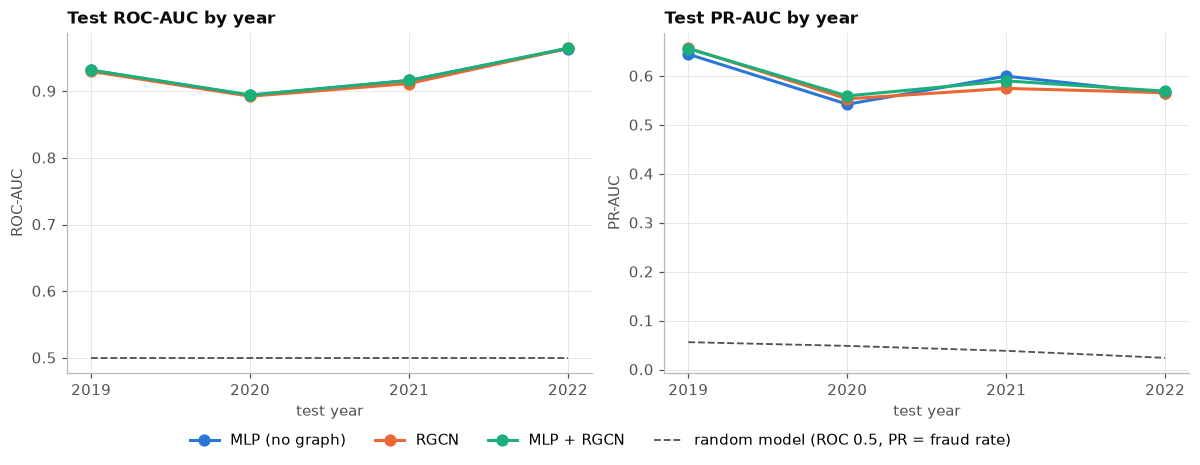

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fraud_rate = results[results["model"] == "mlp"].sort_values("test_year")
for ax, metric, title in [(axes[0], "test_auc", "ROC-AUC"), (axes[1], "test_pr_auc", "PR-AUC")]:
    for model_name in MODELS:
        rows = results[results["model"] == model_name].sort_values("test_year")
        ax.plot(rows["test_year"], rows[metric], marker="o", markersize=7, color=COLORS[model_name], label=NAMES[model_name])
    random_level = [0.5] * len(fraud_rate) if metric == "test_auc" else fraud_rate["test_fraud_rate"]
    draw_random_line(ax, fraud_rate["test_year"], random_level, "random model")
    ax.set(title=f"Test {title} by year", xlabel="test year", ylabel=title, xticks=TEST_YEARS)

handles, labels = axes[0].get_legend_handles_labels()
labels[-1] = "random model (ROC 0.5, PR = fraud rate)"
fig.legend(handles, labels, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
save_fig(fig, "metrics_by_year")
plt.show()

### ROC and precision-recall curves

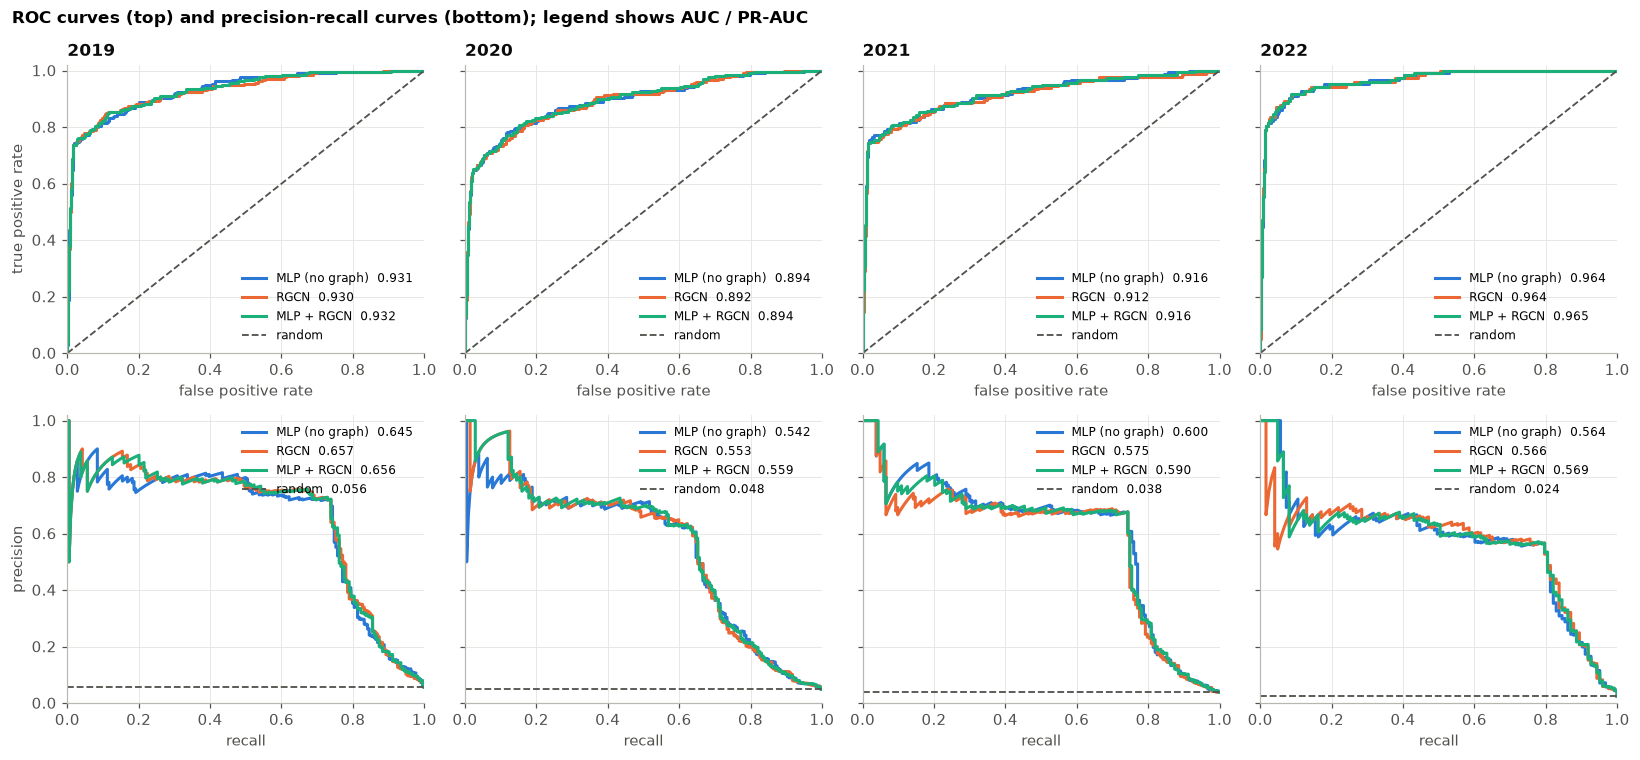

In [21]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 7), sharex=True, sharey="row")
for column, year in enumerate(TEST_YEARS):
    roc_ax, pr_ax = axes[0, column], axes[1, column]
    for model_name in MODELS:
        rows = predictions_for(model_name, year)
        false_positive_rate, true_positive_rate, _ = roc_curve(rows["Label"], rows["score"])
        precision, recall, _ = precision_recall_curve(rows["Label"], rows["score"])
        roc_auc = roc_auc_score(rows["Label"], rows["score"])
        pr_auc = average_precision_score(rows["Label"], rows["score"])
        roc_ax.plot(false_positive_rate, true_positive_rate, color=COLORS[model_name], label=f"{NAMES[model_name]}  {roc_auc:.3f}")
        pr_ax.plot(recall, precision, color=COLORS[model_name], label=f"{NAMES[model_name]}  {pr_auc:.3f}")

    year_fraud_rate = rows["Label"].mean()
    draw_random_line(roc_ax, [0, 1], [0, 1], "random")
    draw_random_line(pr_ax, [0, 1], [year_fraud_rate, year_fraud_rate], f"random  {year_fraud_rate:.3f}")
    roc_ax.set(title=str(year), xlim=(0, 1), ylim=(0, 1.02), xlabel="false positive rate")
    roc_ax.xaxis.set_tick_params(labelbottom=True)
    pr_ax.set(xlabel="recall", ylim=(0, 1.02))
    roc_ax.legend(fontsize=8, loc="lower right")
    pr_ax.legend(fontsize=8, loc="upper right")

axes[0, 0].set_ylabel("true positive rate")
axes[1, 0].set_ylabel("precision")
fig.suptitle("ROC curves (top) and precision-recall curves (bottom); legend shows AUC / PR-AUC", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "roc_pr_curves")
plt.show()

### Frauds caught when reviewing the top-scored companies

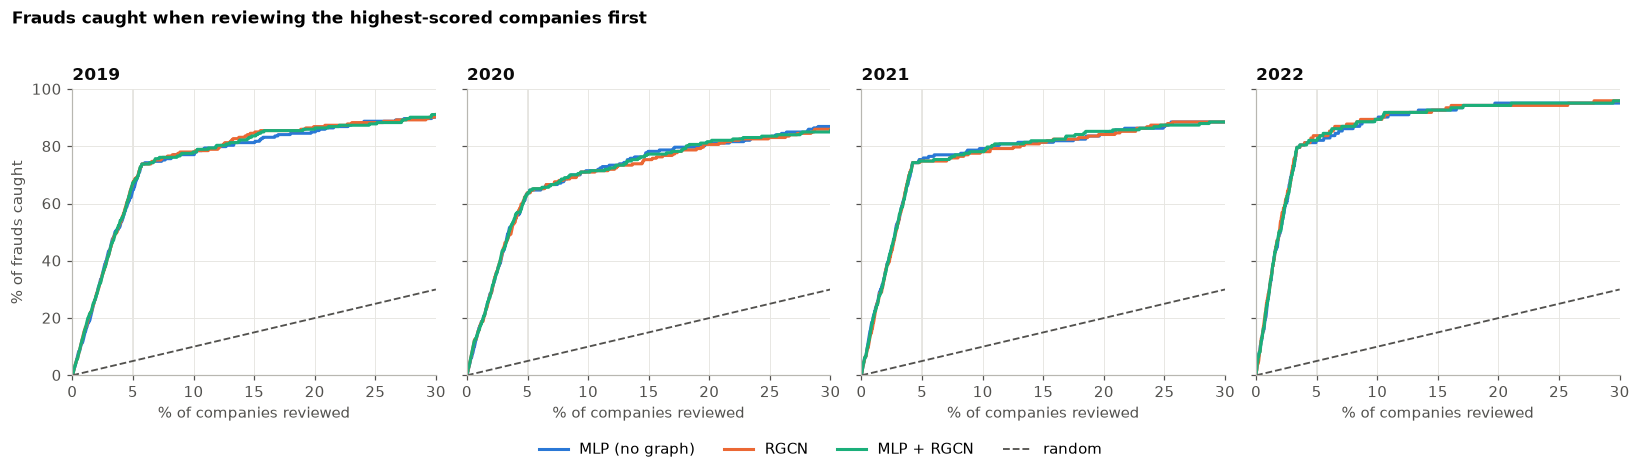

In [22]:
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(15, 3.8), sharey=True)
for ax, year in zip(axes, TEST_YEARS):
    for model_name in MODELS:
        ranked_labels = (predictions_for(model_name, year).sort_values("score", ascending=False)["Label"].to_numpy())
        share_reviewed = np.arange(1, len(ranked_labels) + 1) / len(ranked_labels)
        share_caught = np.cumsum(ranked_labels) / ranked_labels.sum()
        ax.plot(share_reviewed * 100, share_caught * 100, color=COLORS[model_name], label=NAMES[model_name])
    draw_random_line(ax, [0, 30], [0, 30], "random")
    ax.axvline(5, color=GRID, linewidth=1.2, zorder=0)
    ax.set(title=str(year), xlim=(0, 30), ylim=(0, 100), xlabel="% of companies reviewed")

axes[0].set_ylabel("% of frauds caught")
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Frauds caught when reviewing the highest-scored companies first", x=0.01, ha="left", y=1.02, fontsize=11, fontweight="bold")
fig.tight_layout()
fig.legend(handles, labels, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
save_fig(fig, "capture_curves")
plt.show()

### Precision and recall at the top 1%, 5% and 10%

In [23]:
top_share_rows = []
for (model_name, year), rows in predictions.groupby(["model", "Year"]):
    ranked = rows.sort_values("score", ascending=False)
    for share in (0.01, 0.05, 0.10):
        flagged = ranked.head(int(np.ceil(share * len(ranked))))
        top_share_rows.append({"model": NAMES[model_name],
                               "test_year": year,
                               "top_%_reviewed": int(share * 100),
                               "precision": flagged["Label"].mean(),
                               "recall": flagged["Label"].sum() / ranked["Label"].sum()})

top_share_table = (pd.DataFrame(top_share_rows).pivot_table(index=["top_%_reviewed", "test_year"], columns="model", values=["precision", "recall"]).round(3))
top_share_table.to_csv(RESULTS_DIR / "topk_precision_recall.csv")
top_share_table

precision                           recall  \
model                    MLP (no graph) MLP + RGCN   RGCN MLP (no graph)   
top_%_reviewed test_year                                                   
1              2019               0.795      0.872  0.872          0.145   
               2020               0.791      0.767  0.767          0.164   
               2021               0.792      0.771  0.708          0.208   
               2022               0.654      0.635  0.673          0.276   
5              2019               0.728      0.754  0.754          0.650   
               2020               0.617      0.612  0.617          0.638   
               2021               0.577      0.573  0.573          0.754   
               2022               0.393      0.393  0.401          0.821   
10             2019               0.432      0.437  0.437          0.771   
               2020               0.347      0.344  0.344          0.715   
               2021               0.304      0.300  0.300          0.792   
               2022               0.214      0.214  0.214          0.894   

                                            
model                    MLP + RGCN   RGCN  
top_%_reviewed test_year                    
1              2019           0.159  0.159  
               2020           0.159  0.159  
               2021           0.202  0.186  
               2022           0.268  0.285  
5              2019           0.673  0.673  
               2020           0.633  0.638  
               2021           0.749  0.749  
               2022           0.821  0.837  
10             2019           0.780  0.780  
               2020           0.710  0.710  
               2021           0.781  0.781  
               2022           0.894  0.894

### Training curves

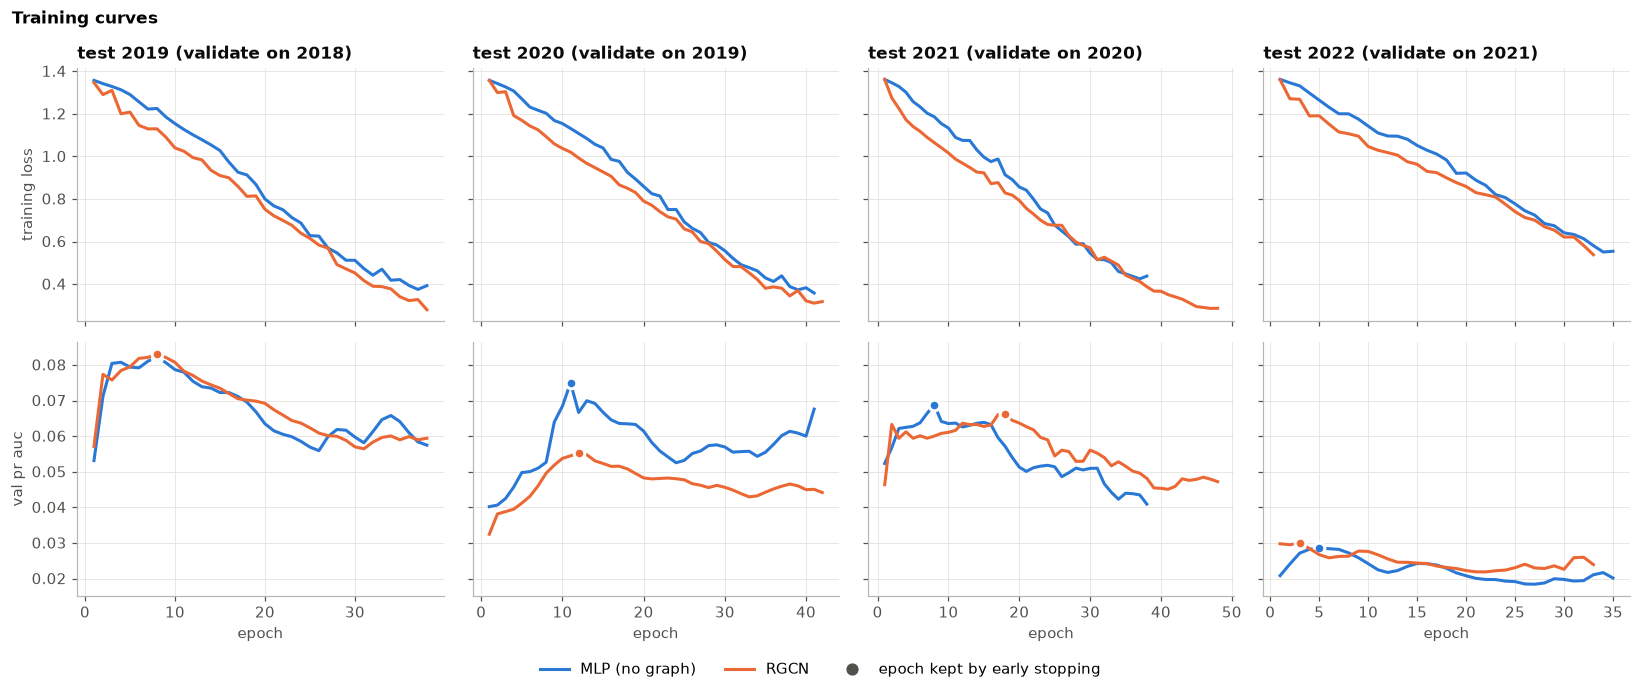

In [24]:
stop_column = f"val_{TRAINING_SETTINGS['stop_metric']}"
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 6), sharex="col", sharey="row")
for column, year in enumerate(TEST_YEARS):
    for model_name in TRAINED_MODELS:
        history = histories[(histories["model"] == model_name) & (histories["test_year"] == year)]
        best = history.loc[history[stop_column].idxmax()]
        axes[0, column].plot(history["epoch"], history["loss"], color=COLORS[model_name])
        axes[1, column].plot(history["epoch"], history[stop_column], color=COLORS[model_name])
        axes[1, column].plot(best["epoch"], best[stop_column], "o", markersize=7, color=COLORS[model_name], markeredgecolor="white", markeredgewidth=2)
    axes[0, column].set_title(f"test {year} (validate on {year - 1})")
    axes[1, column].set_xlabel("epoch")

axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel(stop_column.replace("_", " "))
handles = [Line2D([], [], color=COLORS[model_name], label=NAMES[model_name]) for model_name in TRAINED_MODELS]
handles.append(Line2D([], [], linestyle="", marker="o", markersize=7, color=INK_2, label="epoch kept by early stopping"))
fig.suptitle("Training curves", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.05))
save_fig(fig, "training_curves")
plt.show()

### Confusion matrices

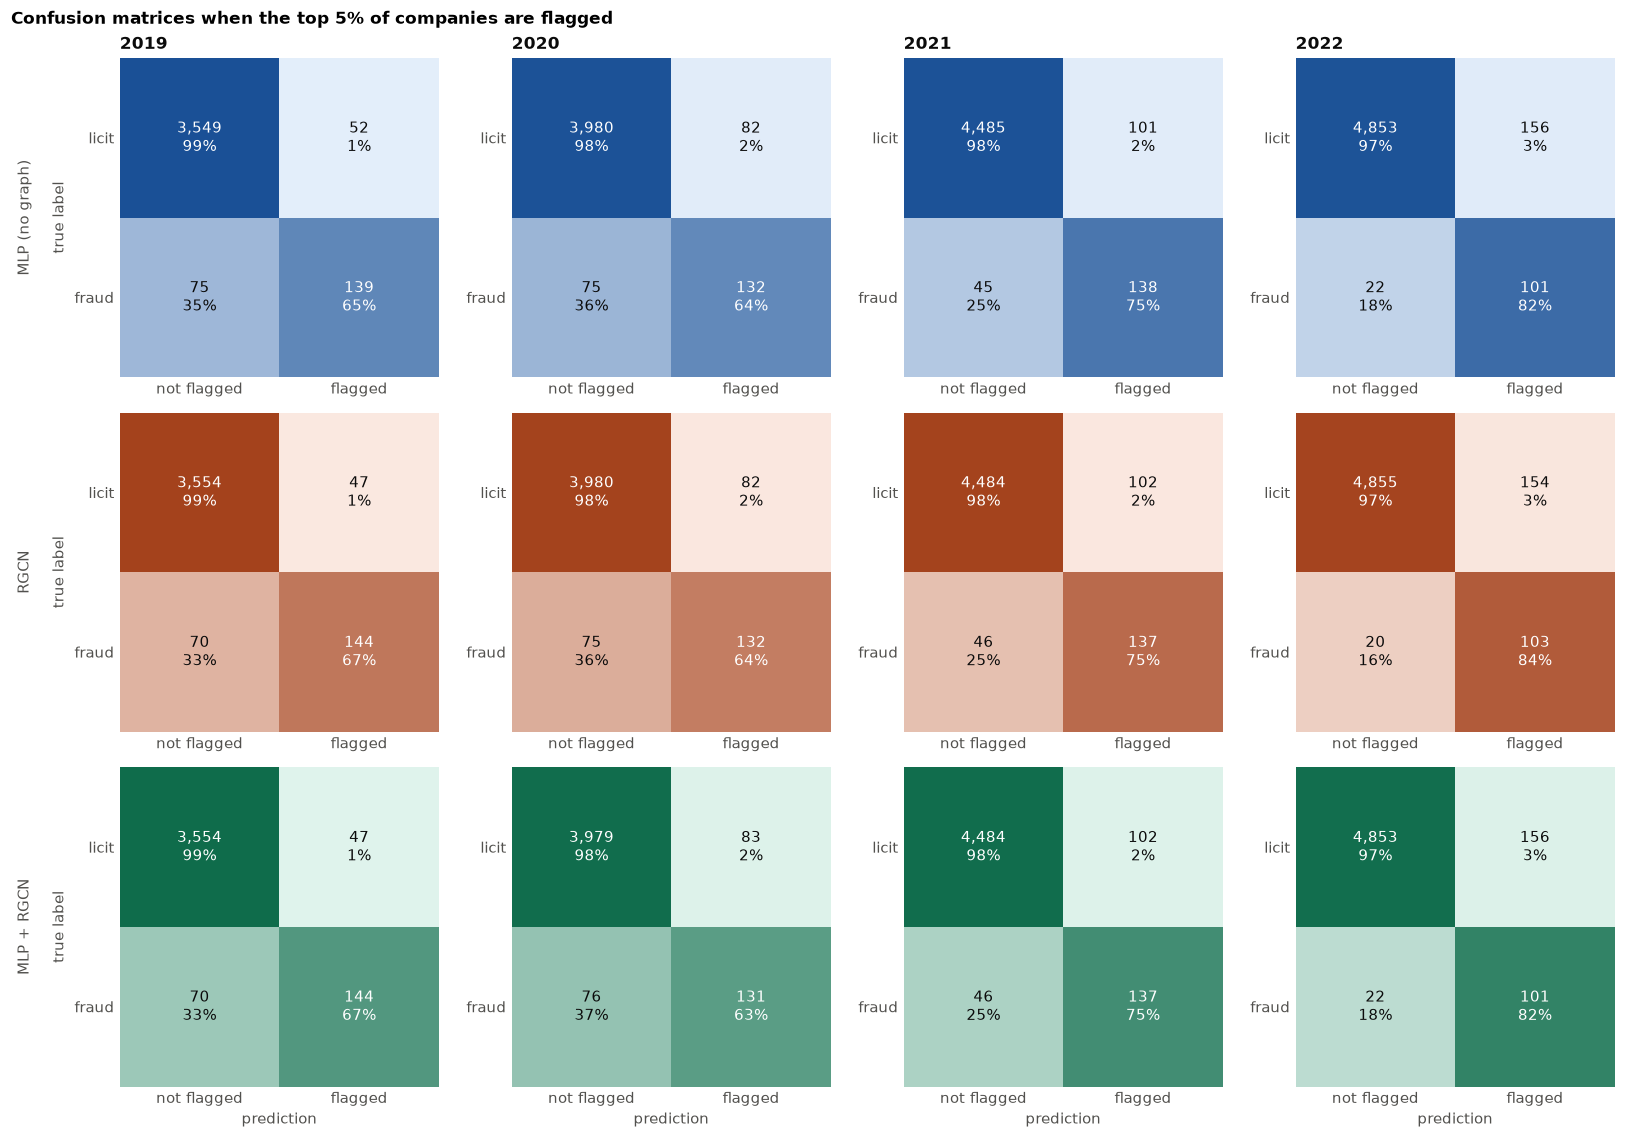

,model,test_year,TP,FP,FN,TN,precision,recall
0,MLP (no graph),2019,139,52,75,3549,0.728,0.650
1,MLP (no graph),2020,132,82,75,3980,0.617,0.638
2,MLP (no graph),2021,138,101,45,4485,0.577,0.754
3,MLP (no graph),2022,101,156,22,4853,0.393,0.821
4,RGCN,2019,144,47,70,3554,0.754,0.673
5,RGCN,2020,132,82,75,3980,0.617,0.638
6,RGCN,2021,137,102,46,4484,0.573,0.749
7,RGCN,2022,103,154,20,4855,0.401,0.837
8,MLP + RGCN,2019,144,47,70,3554,0.754,0.673
9,MLP + RGCN,2020,131,83,76,3979,0.612,0.633


In [25]:
COLOR_RAMPS = {"mlp": ["#e6f0fc", "#184f95"], "rgcn": ["#fcebe3", "#a3401a"], "ens": ["#e2f5ee", "#0d6b4a"]}

fig, axes = plt.subplots(len(MODELS), len(TEST_YEARS), figsize=(15, 3.5 * len(MODELS)))
confusion_rows = []
for row, model_name in enumerate(MODELS):
    color_map = LinearSegmentedColormap.from_list(model_name, COLOR_RAMPS[model_name])
    for column, year in enumerate(TEST_YEARS):
        rows = predictions_for(model_name, year)
        n_flagged = int(np.ceil(FLAG_SHARE * len(rows)))
        flagged = np.zeros(len(rows), dtype=int)
        flagged[np.argsort(-rows["score"].to_numpy())[:n_flagged]] = 1
        counts = confusion_matrix(rows["Label"], flagged, labels=[0, 1])
        shares = counts / counts.sum(axis=1, keepdims=True)

        ax = axes[row, column]
        ax.imshow(shares, cmap=color_map, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{counts[i, j]:,}\n{shares[i, j]:.0%}", ha="center", va="center", fontsize=10, color="white" if shares[i, j] > 0.5 else INK)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged"], yticklabels=["licit", "fraud"])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.tick_params(length=0)
        if row == 0:
            ax.set_title(str(year))
        if column == 0:
            ax.set_ylabel(f"{NAMES[model_name]}\n\ntrue label")
        if row == len(MODELS) - 1:
            ax.set_xlabel("prediction")

        true_negative, false_positive, false_negative, true_positive = counts.ravel()
        confusion_rows.append({"model": NAMES[model_name],
                               "test_year": year,
                               "TP": true_positive,
                               "FP": false_positive,
                               "FN": false_negative,
                               "TN": true_negative,
                               "precision": true_positive / (true_positive + false_positive),
                               "recall": true_positive / (true_positive + false_negative)})

fig.suptitle(f"Confusion matrices when the top {FLAG_SHARE:.0%} of companies are flagged", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

confusion_table = pd.DataFrame(confusion_rows).round(3)
confusion_table.to_csv(RESULTS_DIR / "confusion_matrices.csv", index=False)
confusion_table

## Diagnostics

### Repeat vs first-time frauds

In [26]:
fraud_last_year_table = company_years.assign(Year=company_years["Year"] + 1).rename(columns={"Label": "fraud_last_year"})
diagnosis = (predictions
             .merge(fraud_last_year_table, on=KEYS, how="left")
             .fillna({"fraud_last_year": 0}))
rank_in_year = diagnosis.groupby(["model", "Year"])["model_score"].rank(ascending=False, method="first")
year_size = diagnosis.groupby(["model", "Year"])["model_score"].transform("size")
diagnosis["flagged"] = rank_in_year <= np.ceil(FLAG_SHARE * year_size)
diagnosis["fraud_type"] = np.where(diagnosis["fraud_last_year"] == 1, "repeat fraud", "first-time fraud")

display(diagnosis[diagnosis["flagged"]]
        .groupby(["Year", "model"])["fraud_last_year"]
        .mean()
        .unstack("model")[MODELS].rename(columns=NAMES)
        .round(3)
        .rename_axis(columns="share of flagged companies that were fraud last year"))

(diagnosis[diagnosis["Label"] == 1]
 .groupby(["fraud_type", "Year", "model"])["flagged"]
 .mean()
 .unstack("model")[MODELS].rename(columns=NAMES)
 .round(3))

share of flagged companies that were fraud last year,MLP (no graph),RGCN,MLP + RGCN
Year,,,
2019,0.000,0.309,0.005
2020,0.000,0.005,0.000
2021,0.234,0.230,0.247
2022,0.093,0.000,0.000


model                  MLP (no graph)   RGCN  MLP + RGCN
fraud_type       Year                                   
first-time fraud 2019           0.196  0.161       0.196
                 2020           0.224  0.211       0.211
                 2021           0.106  0.085       0.106
                 2022           0.320  0.440       0.440
repeat fraud     2019           0.000  0.304       0.006
                 2020           0.000  0.008       0.000
                 2021           0.316  0.301       0.324
                 2022           0.153  0.000       0.000

### True positives at 5% under three rankings

In [27]:
def true_positives(frame, score_column):
    groups = [frame["model"], frame["Year"]]
    rank = frame.groupby(groups)[score_column].rank(ascending=False, method="first")
    size = frame.groupby(groups)[score_column].transform("size")
    return (frame["Label"] * (rank <= np.ceil(FLAG_SHARE * size))).groupby(groups).sum()

ranked = diagnosis.assign(fraud_last_year_first=diagnosis["fraud_last_year"] + diagnosis["model_score"], fraud_last_year_only=diagnosis["fraud_last_year"])
(pd.concat({"model ranking": true_positives(ranked, "model_score"),
            "fraud last year first, then model": true_positives(ranked, "fraud_last_year_first"),
            "fraud last year only": true_positives(ranked, "fraud_last_year_only")}, axis=1)
   .unstack("model")
   .reindex(columns=MODELS, level="model")
   .rename(columns=NAMES))

model ranking                 fraud last year first, then model       \
model MLP (no graph) RGCN MLP + RGCN                    MLP (no graph) RGCN   
Year                                                                          
2019              11   57         12                               139  144   
2020              17   17         16                               132  132   
2021              48   45         49                               138  137   
2022              23   11         11                               101  103   

                 fraud last year only                  
model MLP + RGCN       MLP (no graph) RGCN MLP + RGCN  
Year                                                   
2019         144                  140  140        140  
2020         131                  131  131        131  
2021         137                  137  137        137  
2022         101                   98   98         98